<a href="https://colab.research.google.com/github/ArshSaran/ShopInsight-AI/blob/main/notebooks/ShopInsight_Milestone1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# ShopInsight AI
### E-Commerce Purchase Prediction and Decision Support

**Course:** CMPT 310 – Artificial Intelligence  
**Group:** 13  
**Milestone:** 1 – Progress and Baseline Implementation

---

## 1. Project Overview

### 1.1 Problem Statement

ShopInsight AI aims to predict whether an online shopping session will result in a purchase based on the visitor's browsing activity.

This is a supervised binary classification problem. The system learns patterns from historical shopping sessions to predict purchase outcomes and estimate purchase probabilities.

### 1.2 Dataset

**Name:** Online Shoppers Purchasing Intention Dataset  
**Source:** UCI Machine Learning Repository  
**Original Sessions:** 12,330  
**Sessions After Removing Duplicates:** 12,205  
**Input Features:** 17  
**Target Variable:** Revenue

The dataset contains session-level information such as page visits, browsing duration, visitor type, month, and other browsing-related attributes.

### 1.3 Input and Output

**Input:** 17 features describing an online shopping session.

**Output:**
- Purchase (Revenue = True)
- No Purchase (Revenue = False)
- Estimated probability of purchase

### 1.4 Milestone 1 Objectives

1. Load and explore the dataset.
2. Examine data quality, feature distributions, and class imbalance.
3. Clean and preprocess the data for machine learning.
4. Train Logistic Regression, Decision Tree, and KNN baseline models.
5. Evaluate and compare models using classification metrics and visualizations.
6. Investigate the effect of removing PageValues.
7. Experiment with balanced class weights and decision thresholds.
8. Demonstrate individual purchase predictions and probabilities.
9. Identify limitations and plan improvements for the next milestone.



## 2. Dataset Loading

### 2.1 Dataset Source

We use the **Online Shoppers Purchasing Intention Dataset** from the UCI Machine Learning Repository.

The dataset contains 12,330 online shopping sessions, described by 17 input features and one target variable (`Revenue`).

- **Features (X):** Information about visitor browsing activity and session characteristics.
- **Target (y):** Whether the session resulted in a purchase (`True`) or no purchase (`False`).

The dataset is loaded directly from UCI using the `ucimlrepo` Python package to make the data-loading process reproducible.

### 2.2 Loading the Dataset

The following code retrieves the dataset, separates the input features from the target variable, and combines them into a DataFrame for exploratory analysis.

In [1]:

# ==================================================
# SECTION 2: DATASET LOADING
# ==================================================

# Install the UCI dataset package
%pip -q install ucimlrepo

# Import required libraries
import pandas as pd
import numpy as np
from ucimlrepo import fetch_ucirepo

# Load the Online Shoppers Purchasing Intention Dataset
shopping = fetch_ucirepo(id=468)

# Separate input features and target variable
X = shopping.data.features.copy()
y = shopping.data.targets.copy()

# Combine features and target for exploratory analysis
df = X.copy()
df["Revenue"] = y["Revenue"].values

# Verify successful loading
print("Dataset loaded successfully!")
print("-" * 40)
print(f"Total Sessions: {df.shape[0]}")
print(f"Input Features: {X.shape[1]}")
print(f"Total Columns (including target): {df.shape[1]}")

# Display first five rows
print("\nFirst Five Rows:")
display(df.head())

Dataset loaded successfully!
----------------------------------------
Total Sessions: 12330
Input Features: 17
Total Columns (including target): 18

First Five Rows:


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False



### 2.3 Dataset Loading Result

The dataset was loaded successfully, containing **12,330 sessions, 17 input features, and one binary target variable**. The data is now available for exploratory analysis and subsequent model development.


## 3. Exploratory Data Analysis (EDA)

Before training our models, we first explore the dataset to understand the features, check the data quality, and see how purchase and non-purchase sessions are distributed.

### 3.1 Dataset Structure and Data Quality

We check the number of rows and columns, the data types, missing values, and duplicate rows. This helps us understand the dataset and decide what needs to be handled before training our models.


In [2]:

# ==================================================
# SECTION 3.1: DATASET STRUCTURE AND DATA QUALITY
# ==================================================

# Dataset dimensions
print("DATASET STRUCTURE")
print("-" * 45)
print(f"Number of Sessions: {df.shape[0]}")
print(f"Number of Input Features: {X.shape[1]}")
print(f"Total Columns: {df.shape[1]}")

# Column names and data types
print("\nCOLUMN INFORMATION")
print("-" * 45)
df.info()

# Missing values
print("\nMISSING VALUES")
print("-" * 45)
missing_values = df.isnull().sum()
display(missing_values.to_frame(name="Missing Values"))

print(f"Total Missing Values: {missing_values.sum()}")

# Duplicate rows
print("\nDUPLICATE ROWS")
print("-" * 45)
duplicate_count = df.duplicated().sum()
duplicate_percentage = duplicate_count / len(df) * 100

print(f"Duplicate Rows: {duplicate_count}")
print(f"Duplicate Percentage: {duplicate_percentage:.2f}%")

DATASET STRUCTURE
---------------------------------------------
Number of Sessions: 12330
Number of Input Features: 17
Total Columns: 18

COLUMN INFORMATION
---------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-

,Missing Values
Administrative,0
Administrative_Duration,0
Informational,0
Informational_Duration,0
ProductRelated,0
ProductRelated_Duration,0
BounceRates,0
ExitRates,0
PageValues,0
SpecialDay,0


Total Missing Values: 0

DUPLICATE ROWS
---------------------------------------------
Duplicate Rows: 125
Duplicate Percentage: 1.01%



**Findings:**

- Our dataset has 12,330 shopping sessions, 17 input features, and one target variable (`Revenue`).
- All 18 columns have complete data, with no missing values.
- We found 125 duplicate rows (1.01%). We will investigate these before deciding whether to remove them.
- The dataset contains numerical, categorical, and Boolean features. Some categorical features are stored as numbers, so we will need to encode them properly before training.
- Since there are no missing values, we do not need missing-value imputation.



### 3.2 Purchase Class Distribution

We check how many shopping sessions resulted in a purchase (`Revenue = True`) and how many did not (`Revenue = False`).

We also calculate the percentages and class imbalance ratio. This is important because if one class has many more sessions than the other, accuracy alone may not be enough to evaluate our models.

PURCHASE CLASS DISTRIBUTION
---------------------------------------------
No Purchase: 10422
Purchase: 1908

PURCHASE PERCENTAGES
---------------------------------------------
No Purchase: 84.53%
Purchase: 15.47%

CLASS IMBALANCE RATIO
---------------------------------------------
No Purchase : Purchase = 5.46:1


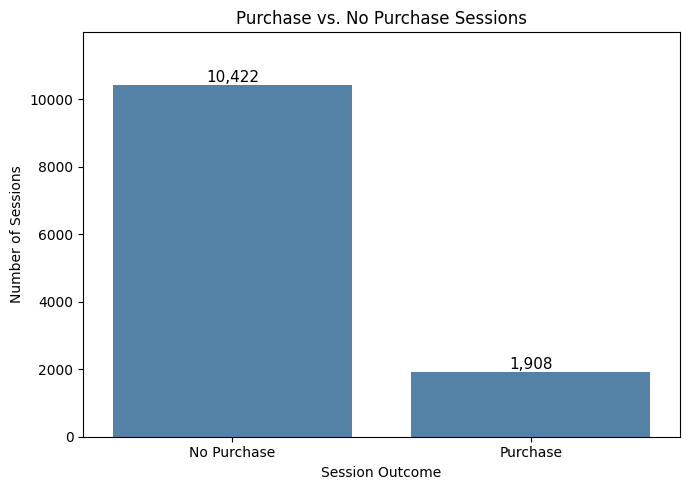

In [3]:

# ==================================================
# SECTION 3.2: PURCHASE CLASS DISTRIBUTION
# ==================================================

import matplotlib.pyplot as plt
import seaborn as sns

# Count purchase and non-purchase sessions
purchase_counts = df["Revenue"].value_counts().reindex(
    [False, True], fill_value=0
)

# Calculate percentages
purchase_percentages = purchase_counts / len(df) * 100

# Calculate imbalance ratio
imbalance_ratio = (
    purchase_counts[False] / purchase_counts[True]
)

# Display results
print("PURCHASE CLASS DISTRIBUTION")
print("-" * 45)

print(f"No Purchase: {purchase_counts[False]}")
print(f"Purchase: {purchase_counts[True]}")

print("\nPURCHASE PERCENTAGES")
print("-" * 45)

print(f"No Purchase: {purchase_percentages[False]:.2f}%")
print(f"Purchase: {purchase_percentages[True]:.2f}%")

print("\nCLASS IMBALANCE RATIO")
print("-" * 45)
print(f"No Purchase : Purchase = {imbalance_ratio:.2f}:1")

# Create purchase distribution graph
plt.figure(figsize=(7, 5))

ax = sns.barplot(
    x=["No Purchase", "Purchase"],
    y=purchase_counts.values,
    color="steelblue"
)

# Add counts above each bar
for i, count in enumerate(purchase_counts.values):
    ax.text(
        i, count + 100,
        f"{count:,}",
        ha="center",
        fontsize=11
    )

plt.title("Purchase vs. No Purchase Sessions")
plt.xlabel("Session Outcome")
plt.ylabel("Number of Sessions")
plt.ylim(0, purchase_counts.max() * 1.15)

plt.tight_layout()

# Save figure for the Milestone 1 report
plt.savefig("purchase_distribution.png", dpi=300)

plt.show()


**Findings:**

- Out of 12,330 shopping sessions, 10,422 (84.53%) did not result in a purchase, while 1,908 (15.47%) resulted in a purchase.
- The class imbalance ratio is 5.46:1, meaning non-purchase sessions are much more common.
- This imbalance could cause our models to favour predicting "No Purchase."
- Because of this, we will use precision, recall, F1-score, and other evaluation metrics instead of relying only on accuracy.



### 3.3 Summary Statistics

We look at the numerical features to understand their ranges, averages, and distributions. We also check for features with unusually large values.

This helps us understand the data better and decide what preprocessing is needed before training our models.


In [4]:

# ==================================================
# SECTION 3.3: SUMMARY STATISTICS
# ==================================================

# Select numerical features
numerical_features = [
    "Administrative",
    "Administrative_Duration",
    "Informational",
    "Informational_Duration",
    "ProductRelated",
    "ProductRelated_Duration",
    "BounceRates",
    "ExitRates",
    "PageValues",
    "SpecialDay"
]

# Calculate summary statistics
summary_stats = df[numerical_features].describe().T

# Display statistics
print("SUMMARY STATISTICS")
print("-" * 45)

display(summary_stats.round(2))

# Check features with the largest ranges
feature_ranges = (
    df[numerical_features].max()
    - df[numerical_features].min()
).sort_values(ascending=False)

print("\nFEATURE RANGES")
print("-" * 45)

display(feature_ranges.to_frame(name="Range").round(2))

# Check skewness of numerical features
print("\nFEATURE SKEWNESS")
print("-" * 45)

skewness = df[numerical_features].skew().sort_values(
    ascending=False
)

display(skewness.to_frame(name="Skewness").round(2))


SUMMARY STATISTICS
---------------------------------------------


,count,mean,std,min,25%,50%,75%,max
Administrative,12330.0,2.32,3.32,0.0,0.00,1.00,4.00,27.00
Administrative_Duration,12330.0,80.82,176.78,0.0,0.00,7.50,93.26,3398.75
Informational,12330.0,0.50,1.27,0.0,0.00,0.00,0.00,24.00
Informational_Duration,12330.0,34.47,140.75,0.0,0.00,0.00,0.00,2549.38
ProductRelated,12330.0,31.73,44.48,0.0,7.00,18.00,38.00,705.00
ProductRelated_Duration,12330.0,1194.75,1913.67,0.0,184.14,598.94,1464.16,63973.52
BounceRates,12330.0,0.02,0.05,0.0,0.00,0.00,0.02,0.20
ExitRates,12330.0,0.04,0.05,0.0,0.01,0.03,0.05,0.20
PageValues,12330.0,5.89,18.57,0.0,0.00,0.00,0.00,361.76
SpecialDay,12330.0,0.06,0.20,0.0,0.00,0.00,0.00,1.00



FEATURE RANGES
---------------------------------------------


,Range
ProductRelated_Duration,63973.52
Administrative_Duration,3398.75
Informational_Duration,2549.38
ProductRelated,705.00
PageValues,361.76
Administrative,27.00
Informational,24.00
SpecialDay,1.00
ExitRates,0.20
BounceRates,0.20



FEATURE SKEWNESS
---------------------------------------------


,Skewness
Informational_Duration,7.58
ProductRelated_Duration,7.26
PageValues,6.38
Administrative_Duration,5.62
ProductRelated,4.34
Informational,4.04
SpecialDay,3.30
BounceRates,2.95
ExitRates,2.15
Administrative,1.96



**Findings:**

- The numerical features have very different ranges. For example, `ProductRelated_Duration` reaches 63,973.52, while `BounceRates` only reaches 0.20.
- Some features are highly right-skewed, especially `Informational_Duration`, `ProductRelated_Duration`, and `PageValues`. This means most sessions have smaller values, while a few have much larger values.
- Visitors viewed around 31.73 product-related pages per session on average, but the median was only 18.
- The median `PageValues` is 0, so at least half of the sessions have a value of zero.
- These results show that we should consider feature scaling before training models like Logistic Regression and KNN. We will also investigate `PageValues` more closely.



### 3.4 Data Visualizations

We create graphs to better understand how visitors behave during shopping sessions and how different features relate to purchases.

We focus on product page visits, browsing duration, `PageValues`, and visitor type. This will help us identify useful patterns and understand which features may be important for our models.


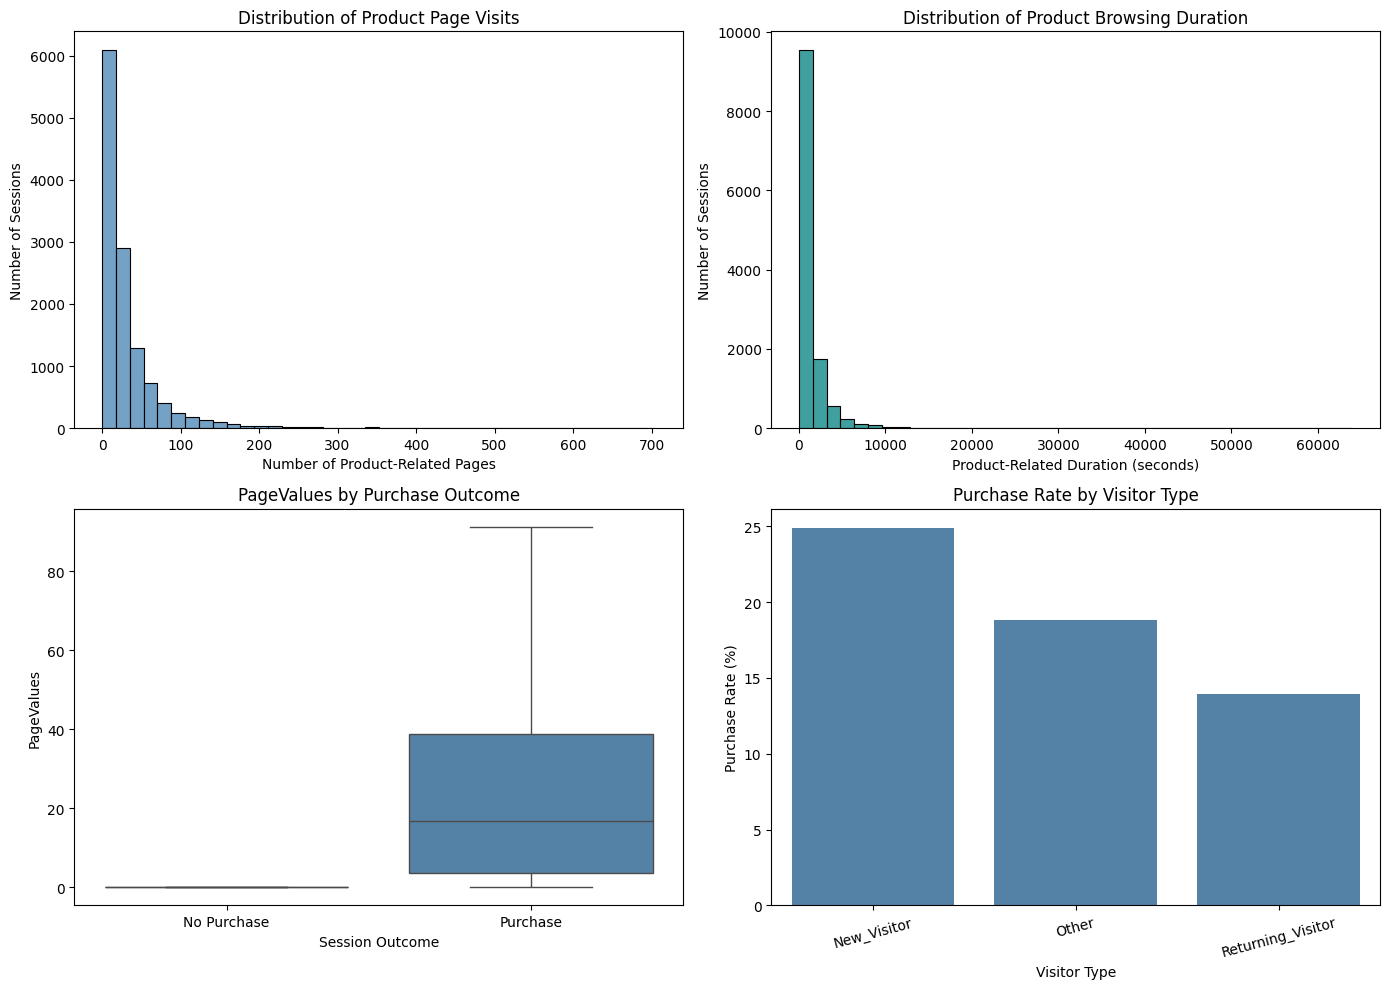

PURCHASE RATE BY VISITOR TYPE
---------------------------------------------


,Purchase Rate (%)
VisitorType,
New_Visitor,24.91
Other,18.82
Returning_Visitor,13.93



PAGEVALUES BY PURCHASE OUTCOME
---------------------------------------------


,count,mean,median
Revenue,,,
False,10422,1.98,0.00
True,1908,27.26,16.76


In [5]:

# ==================================================
# SECTION 3.4: DATA VISUALIZATIONS
# ==================================================

import matplotlib.pyplot as plt
import seaborn as sns

# Create a figure with four graphs
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# --------------------------------------------------
# Graph 1: Product-Related Page Visits
# --------------------------------------------------

sns.histplot(
    data=df,
    x="ProductRelated",
    bins=40,
    color="steelblue",
    ax=axes[0, 0]
)

axes[0, 0].set_title("Distribution of Product Page Visits")
axes[0, 0].set_xlabel("Number of Product-Related Pages")
axes[0, 0].set_ylabel("Number of Sessions")

# --------------------------------------------------
# Graph 2: Product-Related Browsing Duration
# --------------------------------------------------

sns.histplot(
    data=df,
    x="ProductRelated_Duration",
    bins=40,
    color="teal",
    ax=axes[0, 1]
)

axes[0, 1].set_title("Distribution of Product Browsing Duration")
axes[0, 1].set_xlabel("Product-Related Duration (seconds)")
axes[0, 1].set_ylabel("Number of Sessions")

# --------------------------------------------------
# Graph 3: PageValues vs Purchase
# --------------------------------------------------

sns.boxplot(
    data=df,
    x="Revenue",
    y="PageValues",
    showfliers=False,
    color="steelblue",
    ax=axes[1, 0]
)

axes[1, 0].set_title("PageValues by Purchase Outcome")
axes[1, 0].set_xlabel("Session Outcome")
axes[1, 0].set_ylabel("PageValues")
axes[1, 0].set_xticks([0, 1])
axes[1, 0].set_xticklabels(["No Purchase", "Purchase"])

# --------------------------------------------------
# Graph 4: Purchase Rate by Visitor Type
# --------------------------------------------------

visitor_purchase_rate = (
    df.groupby("VisitorType")["Revenue"].mean() * 100
).sort_values(ascending=False)

sns.barplot(
    x=visitor_purchase_rate.index,
    y=visitor_purchase_rate.values,
    color="steelblue",
    ax=axes[1, 1]
)

axes[1, 1].set_title("Purchase Rate by Visitor Type")
axes[1, 1].set_xlabel("Visitor Type")
axes[1, 1].set_ylabel("Purchase Rate (%)")
axes[1, 1].tick_params(axis="x", rotation=15)

# Improve layout
plt.tight_layout()

# Save figure for Milestone 1
plt.savefig("milestone1_visualizations.png", dpi=300)

plt.show()

# Display exact purchase rates
print("PURCHASE RATE BY VISITOR TYPE")
print("-" * 45)
display(visitor_purchase_rate.round(2).to_frame(
    name="Purchase Rate (%)"
))

# Compare PageValues between purchase outcomes
print("\nPAGEVALUES BY PURCHASE OUTCOME")
print("-" * 45)

pagevalues_summary = df.groupby("Revenue")["PageValues"].agg(
    ["count", "mean", "median"]
)

display(pagevalues_summary.round(2))



**Findings:**

- Most visitors view relatively few product pages and spend less time browsing, while a small number of sessions have much higher values.
- `PageValues` is much higher for purchase sessions. The average is 27.26 for purchases compared to 1.98 for non-purchases.
- New visitors have the highest purchase rate (24.91%), followed by Other visitors (18.82%) and returning visitors (13.93%).
- These patterns suggest that browsing behaviour and visitor type may help predict purchases.
- We will compare models with and without `PageValues` to check how much our predictions depend on this feature.



## 4. Data Preprocessing

Before training our models, we need to prepare the data so the algorithms can use it correctly. We will identify feature types, handle duplicate records, split the dataset, and apply encoding and scaling where needed.

### 4.1 Identifying Feature Types

Our dataset contains numerical, categorical, and Boolean features. We separate them because different types of features need different preprocessing methods.

Some categorical features, such as `Browser` and `Region`, are stored as numbers, but these numbers represent categories rather than actual measurements.


In [6]:

# ==================================================
# SECTION 4.1: IDENTIFYING FEATURE TYPES
# ==================================================

# Numerical features
numerical_features = [
    "Administrative",
    "Administrative_Duration",
    "Informational",
    "Informational_Duration",
    "ProductRelated",
    "ProductRelated_Duration",
    "BounceRates",
    "ExitRates",
    "PageValues",
    "SpecialDay"
]

# Categorical features
categorical_features = [
    "Month",
    "OperatingSystems",
    "Browser",
    "Region",
    "TrafficType",
    "VisitorType"
]

# Boolean features
boolean_features = [
    "Weekend"
]

# Check that every input feature is included exactly once
all_features = (
    numerical_features
    + categorical_features
    + boolean_features
)

assert len(all_features) == len(set(all_features)), \
    "Some features are listed more than once."

assert set(all_features) == set(X.columns), \
    "Feature lists do not match the dataset."

# Display feature counts
print("FEATURE TYPE IDENTIFICATION")
print("-" * 45)

print(f"Numerical Features: {len(numerical_features)}")
print(f"Categorical Features: {len(categorical_features)}")
print(f"Boolean Features: {len(boolean_features)}")
print(f"Total Input Features: {len(all_features)}")

# Create a summary table
feature_summary = pd.DataFrame({
    "Feature": all_features,
    "Type": (
        ["Numerical"] * len(numerical_features)
        + ["Categorical"] * len(categorical_features)
        + ["Boolean"] * len(boolean_features)
    )
})

print("\nFEATURE SUMMARY")
display(feature_summary)

print("\nAll 17 input features are accounted for.")


FEATURE TYPE IDENTIFICATION
---------------------------------------------
Numerical Features: 10
Categorical Features: 6
Boolean Features: 1
Total Input Features: 17

FEATURE SUMMARY


,Feature,Type
0,Administrative,Numerical
1,Administrative_Duration,Numerical
2,Informational,Numerical
3,Informational_Duration,Numerical
4,ProductRelated,Numerical
5,ProductRelated_Duration,Numerical
6,BounceRates,Numerical
7,ExitRates,Numerical
8,PageValues,Numerical
9,SpecialDay,Numerical



All 17 input features are accounted for.



**Findings:**

- We identified 10 numerical features, 6 categorical features, and 1 Boolean feature.
- Some features, such as `Browser`, `Region`, and `TrafficType`, are stored as numbers but actually represent categories.
- We will use one-hot encoding for categorical features and scaling for numerical features when needed.
- All 17 input features are included, so we can use these feature groups when building our preprocessing pipeline.


### 4.2 Investigating Duplicate Rows

We found 125 duplicate rows during our initial data exploration. Before removing them, we want to check whether they represent repeated records or different shopping sessions with the same information.

We also check whether identical input features have different purchase outcomes. This will help us decide how to handle duplicates before splitting the dataset for training and testing.


In [7]:

# ==================================================
# SECTION 4.2: INVESTIGATING DUPLICATE ROWS
# ==================================================

# 1. Count fully duplicated rows
full_duplicates = df.duplicated().sum()

print("FULL DUPLICATE ROWS")
print("-" * 45)
print(f"Duplicate Rows: {full_duplicates}")
print(f"Duplicate Percentage: {full_duplicates / len(df) * 100:.2f}%")

# 2. Check duplicate input features
feature_duplicates = df.duplicated(
    subset=X.columns.tolist()
).sum()

print("\nDUPLICATE INPUT FEATURES")
print("-" * 45)
print(f"Rows with Repeated Input Features: {feature_duplicates}")

# 3. Check identical inputs with different outcomes
outcome_counts = df.groupby(
    X.columns.tolist(),
    dropna=False
)["Revenue"].nunique()

conflicting_groups = (outcome_counts > 1).sum()

print("\nCONFLICTING PURCHASE OUTCOMES")
print("-" * 45)
print(f"Feature Groups with Different Outcomes: {conflicting_groups}")

# 4. Show examples of fully duplicated rows
print("\nEXAMPLES OF DUPLICATE RECORDS")
print("-" * 45)

duplicate_examples = df[
    df.duplicated(keep=False)
].head(10)

display(duplicate_examples)

# 5. Check the dataset size if duplicates were removed
unique_rows = len(df.drop_duplicates())

print("\nDATASET SIZE COMPARISON")
print("-" * 45)
print(f"Original Sessions: {len(df)}")
print(f"Sessions After Removing Exact Duplicates: {unique_rows}")

# Do not modify the dataset yet
print("\nOriginal dataset remains unchanged.")


FULL DUPLICATE ROWS
---------------------------------------------
Duplicate Rows: 125
Duplicate Percentage: 1.01%

DUPLICATE INPUT FEATURES
---------------------------------------------
Rows with Repeated Input Features: 125

CONFLICTING PURCHASE OUTCOMES
---------------------------------------------
Feature Groups with Different Outcomes: 0

EXAMPLES OF DUPLICATE RECORDS
---------------------------------------------


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
85,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,1,1,1,3,Returning_Visitor,False,False
132,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,3,2,3,3,Returning_Visitor,False,False
158,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,1,1,1,3,Returning_Visitor,False,False
159,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,3,2,3,3,Returning_Visitor,False,False
178,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,3,2,3,3,Returning_Visitor,False,False
252,0,0.0,0,0.0,2,0.0,0.2,0.2,0.0,0.0,Mar,1,1,1,1,Returning_Visitor,False,False
286,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Mar,2,2,1,1,Returning_Visitor,False,False
293,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Mar,1,1,1,1,Returning_Visitor,True,False
298,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Mar,1,1,8,1,Returning_Visitor,False,False
330,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Mar,3,2,3,1,Returning_Visitor,False,False



DATASET SIZE COMPARISON
---------------------------------------------
Original Sessions: 12330
Sessions After Removing Exact Duplicates: 12205

Original dataset remains unchanged.



**Findings:**

- We found 125 fully duplicated rows (1.01%) in the dataset.
- The same 125 rows also have repeated input features, and no conflicting purchase outcomes were found.
- Removing exact duplicates would reduce the dataset from 12,330 to 12,205 sessions.
- Since identical records could appear in both training and testing data, we decided to remove exact duplicates for our initial models.
- We will keep the original dataset unchanged so we can compare results later if needed.


In [8]:

# Create a cleaned copy for model development
df_clean = df.drop_duplicates().reset_index(drop=True)

# Separate features and target
X_clean = df_clean.drop(columns=["Revenue"])
y_clean = df_clean["Revenue"].astype(int)

print("CLEANED DATASET")
print("-" * 45)
print(f"Original Sessions: {len(df)}")
print(f"Cleaned Sessions: {len(df_clean)}")
print(f"Rows Removed: {len(df) - len(df_clean)}")
print(f"Input Features: {X_clean.shape[1]}")
print(f"Target Values: {sorted(y_clean.unique().tolist())}")

CLEANED DATASET
---------------------------------------------
Original Sessions: 12330
Cleaned Sessions: 12205
Rows Removed: 125
Input Features: 17
Target Values: [0, 1]



### 4.3 Train, Validation, and Test Split

We split our cleaned dataset into 70% training, 15% validation, and 15% testing data.

The training set will be used to train our models, the validation set will help us compare models and choose settings, and the test set will be kept separate for final evaluation.

We use stratified splitting to keep the purchase and non-purchase proportions similar across all three sets. We also set a random seed so we can reproduce the same split.


In [9]:

# ==================================================
# SECTION 4.3: TRAIN / VALIDATION / TEST SPLIT
# ==================================================

from sklearn.model_selection import train_test_split

# First split: 70% training, 30% remaining
X_train, X_temp, y_train, y_temp = train_test_split(
    X_clean,
    y_clean,
    test_size=0.30,
    random_state=42,
    stratify=y_clean
)

# Second split: Divide remaining data equally
# 15% validation and 15% testing
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

# Display dataset sizes
print("DATASET SPLIT")
print("-" * 45)

print(f"Training Sessions: {len(X_train)}")
print(f"Validation Sessions: {len(X_val)}")
print(f"Testing Sessions: {len(X_test)}")

print(f"\nTotal Sessions: {len(X_train) + len(X_val) + len(X_test)}")

# Check purchase percentages in each split
print("\nPURCHASE DISTRIBUTION BY SPLIT")
print("-" * 45)

split_summary = pd.DataFrame({
    "Dataset": ["Training", "Validation", "Testing"],
    "Sessions": [len(y_train), len(y_val), len(y_test)],
    "Purchase Rate (%)": [
        y_train.mean() * 100,
        y_val.mean() * 100,
        y_test.mean() * 100
    ]
})

display(split_summary.round(2))

# Check that no row indices overlap
assert set(X_train.index).isdisjoint(X_val.index)
assert set(X_train.index).isdisjoint(X_test.index)
assert set(X_val.index).isdisjoint(X_test.index)

print("\nNo overlapping row indices between splits.")


DATASET SPLIT
---------------------------------------------
Training Sessions: 8543
Validation Sessions: 1831
Testing Sessions: 1831

Total Sessions: 12205

PURCHASE DISTRIBUTION BY SPLIT
---------------------------------------------


,Dataset,Sessions,Purchase Rate (%)
0,Training,8543,15.64
1,Validation,1831,15.62
2,Testing,1831,15.62



No overlapping row indices between splits.



**Findings:**

- We divided the 12,205 cleaned sessions into 8,543 training, 1,831 validation, and 1,831 testing sessions.
- The purchase rate is almost the same in all three sets (around 15.6%) because we used stratified splitting.
- We confirmed that there are no overlapping row indices between the datasets.
- We will use the training set to train our models, the validation set to compare and improve them, and the test set for final evaluation.
- Preprocessing methods will be fitted only on the training data to prevent data leakage.



### 4.4 Categorical Encoding

Our dataset contains six categorical features: Month, OperatingSystems, Browser, Region, TrafficType, and VisitorType.

Some of these features are stored as numbers, but they represent categories rather than numerical measurements.

We will use One-Hot Encoding to convert each category into separate binary columns. This allows our models to use categorical information without assuming an order between categories.

We will fit the encoder using only the training data to avoid data leakage.


In [10]:

# ==================================================
# SECTION 4.4: CATEGORICAL ENCODING
# ==================================================

from sklearn.preprocessing import OneHotEncoder

# Create the One-Hot Encoder
categorical_encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

print("CATEGORICAL ENCODING")
print("-" * 45)

print("Encoding Method: One-Hot Encoding")
print("Number of Categorical Features:", len(categorical_features))

print("\nCATEGORICAL FEATURES")
print("-" * 45)

for feature in categorical_features:
    print(f"- {feature}")

print("\nENCODER SETTINGS")
print("-" * 45)

print("Handle Unknown Categories: ignore")
print("Output Format: Dense Array")

print("\nEncoder created successfully.")
print("Encoder has not been fitted yet.")
print("Original dataset remains unchanged.")


CATEGORICAL ENCODING
---------------------------------------------
Encoding Method: One-Hot Encoding
Number of Categorical Features: 6

CATEGORICAL FEATURES
---------------------------------------------
- Month
- OperatingSystems
- Browser
- Region
- TrafficType
- VisitorType

ENCODER SETTINGS
---------------------------------------------
Handle Unknown Categories: ignore
Output Format: Dense Array

Encoder created successfully.
Encoder has not been fitted yet.
Original dataset remains unchanged.



**Findings:**

- We identified six categorical features that need encoding.
- We created a One-Hot Encoder to convert categories into binary columns.
- We set the encoder to ignore unknown categories so it can handle categories that appear in validation or testing data but not in training data.
- The encoder has not been fitted yet. We will fit it using only the training data as part of our preprocessing pipeline.



### 4.5 Numerical Feature Scaling

Our numerical features have very different ranges. For example, ProductRelated_Duration has much larger values than BounceRates.

We will use StandardScaler to standardize numerical features. This is important for models such as Logistic Regression and KNN because large feature scales can affect training and distance calculations.

The scaler will be fitted only on the training data. The same transformation will then be applied to the validation and testing sets.


In [11]:

# ==================================================
# SECTION 4.5: NUMERICAL FEATURE SCALING
# ==================================================

from sklearn.preprocessing import StandardScaler

# Create the numerical scaler
numerical_scaler = StandardScaler()

print("NUMERICAL FEATURE SCALING")
print("-" * 45)

print("Scaling Method: StandardScaler")
print("Number of Numerical Features:", len(numerical_features))

print("\nNUMERICAL FEATURES")
print("-" * 45)

for feature in numerical_features:
    print(f"- {feature}")

print("\nSCALER SETTINGS")
print("-" * 45)

print("Method: Standardization")
print("Target Training Mean: Approximately 0")
print("Target Training Standard Deviation: Approximately 1")

print("\nScaler created successfully.")
print("Scaler has not been fitted yet.")
print("Original dataset remains unchanged.")


NUMERICAL FEATURE SCALING
---------------------------------------------
Scaling Method: StandardScaler
Number of Numerical Features: 10

NUMERICAL FEATURES
---------------------------------------------
- Administrative
- Administrative_Duration
- Informational
- Informational_Duration
- ProductRelated
- ProductRelated_Duration
- BounceRates
- ExitRates
- PageValues
- SpecialDay

SCALER SETTINGS
---------------------------------------------
Method: Standardization
Target Training Mean: Approximately 0
Target Training Standard Deviation: Approximately 1

Scaler created successfully.
Scaler has not been fitted yet.
Original dataset remains unchanged.



**Findings:**

- We identified 10 numerical features that will be standardized using StandardScaler.
- Standardization will help models such as Logistic Regression, KNN, and Neural Networks work with features that have different scales.
- We created the scaler but have not fitted it yet.
- We will fit it only on the training data and apply the same transformation to the validation and testing sets to avoid data leakage.



### 4.6 Combined Preprocessing Pipeline

We combine our categorical encoding, numerical scaling, and Boolean feature handling into one preprocessing pipeline using ColumnTransformer.

The pipeline is fitted only on the training data. We then use the same fitted pipeline to transform the validation and testing sets.

This ensures that all three datasets are processed consistently without using information from the validation or testing data during training.


In [12]:

# ==================================================
# SECTION 4.6: COMBINED PREPROCESSING PIPELINE
# ==================================================

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer
import numpy as np

# Convert Boolean values to 0 and 1
boolean_transformer = FunctionTransformer(
    lambda x: x.astype(int),
    validate=False
)

# Combine all preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_scaler, numerical_features),
        ("cat", categorical_encoder, categorical_features),
        ("bool", boolean_transformer, boolean_features)
    ],
    remainder="drop"
)

# Fit preprocessing on training data only
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the same fitted transformations
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

# Display results
print("PREPROCESSING PIPELINE")
print("-" * 45)

print("Training Data:", X_train_processed.shape)
print("Validation Data:", X_val_processed.shape)
print("Testing Data:", X_test_processed.shape)

print("\nPREPROCESSING COMPONENTS")
print("-" * 45)

print("Numerical: StandardScaler")
print("Categorical: OneHotEncoder")
print("Boolean: Converted to 0/1")

# Check that all splits have the same number of features
assert X_train_processed.shape[1] == X_val_processed.shape[1]
assert X_train_processed.shape[1] == X_test_processed.shape[1]

# Check that transformed data contains no NaN or infinity
assert np.isfinite(X_train_processed).all()
assert np.isfinite(X_val_processed).all()
assert np.isfinite(X_test_processed).all()

print("\nAll datasets have matching feature dimensions.")
print("No NaN or infinite values found.")
print("Preprocessing fitted on training data only.")
print("Preprocessing completed successfully.")


PREPROCESSING PIPELINE
---------------------------------------------
Training Data: (8543, 73)
Validation Data: (1831, 73)
Testing Data: (1831, 73)

PREPROCESSING COMPONENTS
---------------------------------------------
Numerical: StandardScaler
Categorical: OneHotEncoder
Boolean: Converted to 0/1

All datasets have matching feature dimensions.
No NaN or infinite values found.
Preprocessing fitted on training data only.
Preprocessing completed successfully.



**Findings:**

- We combined numerical scaling, categorical encoding, and Boolean conversion into one preprocessing pipeline.
- After preprocessing, our 17 original input features became 73 processed features because categorical features were expanded using One-Hot Encoding.
- The training, validation, and testing sets contain 8,543, 1,831, and 1,831 sessions respectively.
- All three sets have matching feature dimensions, and no missing or infinite values were found.
- We fitted preprocessing only on the training data and used the same transformations for validation and testing to avoid data leakage.
- Our data is now ready for baseline model training.



## 5. Baseline Model Development

We will train three baseline classification models: Logistic Regression, Decision Tree, and K-Nearest Neighbors (KNN).

These models will help us understand how well different machine learning methods can predict whether a shopping session results in a purchase.

### 5.1 Logistic Regression

We start with Logistic Regression as our first baseline model. It is a supervised classification algorithm that estimates the probability of a purchase.

We train the model using our preprocessed training data and evaluate its initial performance on the validation set.

Since our dataset is imbalanced, we will not rely only on accuracy. We will also calculate precision, recall, F1-score, and ROC-AUC.


In [13]:

# ==================================================
# SECTION 5.1: LOGISTIC REGRESSION BASELINE
# ==================================================

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# Create the Logistic Regression model
logistic_model = LogisticRegression(
    max_iter=2000,
    random_state=42
)

# Train the model
logistic_model.fit(X_train_processed, y_train)

# Predict validation outcomes
logistic_predictions = logistic_model.predict(
    X_val_processed
)

# Predict purchase probabilities
logistic_probabilities = logistic_model.predict_proba(
    X_val_processed
)[:, 1]

# Calculate evaluation metrics
logistic_accuracy = accuracy_score(
    y_val, logistic_predictions
)

logistic_precision = precision_score(
    y_val, logistic_predictions,
    zero_division=0
)

logistic_recall = recall_score(
    y_val, logistic_predictions,
    zero_division=0
)

logistic_f1 = f1_score(
    y_val, logistic_predictions,
    zero_division=0
)

logistic_auc = roc_auc_score(
    y_val, logistic_probabilities
)

# Display results
print("LOGISTIC REGRESSION BASELINE")
print("-" * 45)

print(f"Accuracy:  {logistic_accuracy:.4f}")
print(f"Precision: {logistic_precision:.4f}")
print(f"Recall:    {logistic_recall:.4f}")
print(f"F1-Score:  {logistic_f1:.4f}")
print(f"ROC-AUC:   {logistic_auc:.4f}")

print("\nCONFUSION MATRIX")
print("-" * 45)

logistic_cm = confusion_matrix(
    y_val, logistic_predictions
)

display(pd.DataFrame(
    logistic_cm,
    index=["Actual No Purchase", "Actual Purchase"],
    columns=["Predicted No Purchase", "Predicted Purchase"]
))

print("\nModel trained and evaluated successfully.")


LOGISTIC REGRESSION BASELINE
---------------------------------------------
Accuracy:  0.8886
Precision: 0.7971
Recall:    0.3846
F1-Score:  0.5189
ROC-AUC:   0.8921

CONFUSION MATRIX
---------------------------------------------


,Predicted No Purchase,Predicted Purchase
Actual No Purchase,1517,28
Actual Purchase,176,110



Model trained and evaluated successfully.



**Findings:**

- Our Logistic Regression model achieved 88.86% accuracy, 79.71% precision, 38.46% recall, 51.89% F1-score, and 89.21% ROC-AUC on the validation set.
- The model correctly identified 110 out of 286 actual purchase sessions but missed 176 purchases.
- The high precision shows that most sessions predicted as purchases were actual purchases. However, the low recall shows that many buyers were not detected.
- Since our dataset is imbalanced, accuracy alone is not enough to evaluate the model.
- We will compare Logistic Regression with Decision Tree and KNN, and later investigate class weights and decision thresholds to improve purchase detection.



### 5.2 Decision Tree

Our second baseline model is a Decision Tree classifier. It predicts whether a shopping session results in a purchase by learning decision rules from the input features.

We will train it using the same training data as Logistic Regression and evaluate it on the same validation set.

To reduce overfitting, we will limit the maximum depth of the tree. We will compare its performance using accuracy, precision, recall, F1-score, and ROC-AUC.


In [14]:

# ==================================================
# SECTION 5.2: DECISION TREE BASELINE
# ==================================================

from sklearn.tree import DecisionTreeClassifier

# Create the Decision Tree model
tree_model = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

# Train the model
tree_model.fit(X_train_processed, y_train)

# Predict validation outcomes
tree_predictions = tree_model.predict(
    X_val_processed
)

# Predict purchase probabilities
tree_probabilities = tree_model.predict_proba(
    X_val_processed
)[:, 1]

# Calculate evaluation metrics
tree_accuracy = accuracy_score(
    y_val, tree_predictions
)

tree_precision = precision_score(
    y_val, tree_predictions,
    zero_division=0
)

tree_recall = recall_score(
    y_val, tree_predictions,
    zero_division=0
)

tree_f1 = f1_score(
    y_val, tree_predictions,
    zero_division=0
)

tree_auc = roc_auc_score(
    y_val, tree_probabilities
)

# Display results
print("DECISION TREE BASELINE")
print("-" * 45)

print(f"Accuracy:  {tree_accuracy:.4f}")
print(f"Precision: {tree_precision:.4f}")
print(f"Recall:    {tree_recall:.4f}")
print(f"F1-Score:  {tree_f1:.4f}")
print(f"ROC-AUC:   {tree_auc:.4f}")

print("\nCONFUSION MATRIX")
print("-" * 45)

tree_cm = confusion_matrix(
    y_val, tree_predictions
)

display(pd.DataFrame(
    tree_cm,
    index=["Actual No Purchase", "Actual Purchase"],
    columns=["Predicted No Purchase", "Predicted Purchase"]
))

print("\nDecision Tree trained and evaluated successfully.")


DECISION TREE BASELINE
---------------------------------------------
Accuracy:  0.8979
Precision: 0.7004
Recall:    0.6049
F1-Score:  0.6492
ROC-AUC:   0.9231

CONFUSION MATRIX
---------------------------------------------


,Predicted No Purchase,Predicted Purchase
Actual No Purchase,1471,74
Actual Purchase,113,173



Decision Tree trained and evaluated successfully.



**Findings:**

- Our Decision Tree achieved 89.79% accuracy, 70.04% precision, 60.49% recall, 64.92% F1-score, and 92.31% ROC-AUC on the validation set.
- It correctly identified 173 out of 286 actual purchase sessions and missed 113 purchases.
- Compared with Logistic Regression, the Decision Tree detected 63 more purchases and achieved higher recall, F1-score, accuracy, and ROC-AUC.
- However, its precision was lower because it incorrectly predicted more non-purchase sessions as purchases.
- The Decision Tree is currently our stronger baseline for identifying potential buyers, but we still need to compare it with KNN.



### 5.3 K-Nearest Neighbors (KNN)

Our third baseline model is K-Nearest Neighbors (KNN). It predicts whether a shopping session results in a purchase by comparing it with similar sessions in the training data.

We will use K = 5 as our initial setting. Since KNN calculates distances between sessions, numerical feature scaling is important.

We will evaluate KNN on the same validation set using accuracy, precision, recall, F1-score, and ROC-AUC.


In [15]:

# ==================================================
# SECTION 5.3: KNN BASELINE
# ==================================================

from sklearn.neighbors import KNeighborsClassifier

# Create KNN model
knn_model = KNeighborsClassifier(
    n_neighbors=5
)

# Fit model using training data
knn_model.fit(X_train_processed, y_train)

# Predict validation outcomes
knn_predictions = knn_model.predict(
    X_val_processed
)

# Predict purchase probabilities
knn_probabilities = knn_model.predict_proba(
    X_val_processed
)[:, 1]

# Calculate evaluation metrics
knn_accuracy = accuracy_score(
    y_val, knn_predictions
)

knn_precision = precision_score(
    y_val, knn_predictions,
    zero_division=0
)

knn_recall = recall_score(
    y_val, knn_predictions,
    zero_division=0
)

knn_f1 = f1_score(
    y_val, knn_predictions,
    zero_division=0
)

knn_auc = roc_auc_score(
    y_val, knn_probabilities
)

# Display results
print("KNN BASELINE")
print("-" * 45)

print(f"Accuracy:  {knn_accuracy:.4f}")
print(f"Precision: {knn_precision:.4f}")
print(f"Recall:    {knn_recall:.4f}")
print(f"F1-Score:  {knn_f1:.4f}")
print(f"ROC-AUC:   {knn_auc:.4f}")

print("\nCONFUSION MATRIX")
print("-" * 45)

knn_cm = confusion_matrix(
    y_val, knn_predictions
)

display(pd.DataFrame(
    knn_cm,
    index=["Actual No Purchase", "Actual Purchase"],
    columns=["Predicted No Purchase", "Predicted Purchase"]
))

print("\nKNN trained and evaluated successfully.")


KNN BASELINE
---------------------------------------------
Accuracy:  0.8837
Precision: 0.7325
Recall:    0.4021
F1-Score:  0.5192
ROC-AUC:   0.8067

CONFUSION MATRIX
---------------------------------------------


,Predicted No Purchase,Predicted Purchase
Actual No Purchase,1503,42
Actual Purchase,171,115



KNN trained and evaluated successfully.



**Findings:**

- Our KNN model achieved 88.37% accuracy, 73.25% precision, 40.21% recall, 51.92% F1-score, and 80.67% ROC-AUC on the validation set.
- It correctly identified 115 out of 286 actual purchases but missed 171 purchases.
- KNN performed slightly better than Logistic Regression in recall and F1-score, but Logistic Regression had higher precision, accuracy, and ROC-AUC.
- The Decision Tree performed better than both models in recall, F1-score, accuracy, and ROC-AUC.
- Our results show that detecting purchases is more difficult than predicting non-purchases. We will investigate class imbalance, decision thresholds, and stronger models to improve performance.



### 5.4 Baseline Model Comparison

We compare Logistic Regression, Decision Tree, and KNN using the same validation dataset.

We use accuracy, precision, recall, F1-score, and ROC-AUC to evaluate their performance. Since only around 15.6% of sessions result in purchases, recall and F1-score are especially important.

This comparison helps us identify the strongest baseline and understand which areas need improvement in the next stage of our project.


BASELINE MODEL COMPARISON
-------------------------------------------------------


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.8886,0.7971,0.3846,0.5189,0.8921
1,Decision Tree,0.8979,0.7004,0.6049,0.6492,0.9231
2,KNN,0.8837,0.7325,0.4021,0.5192,0.8067



BEST BASELINE BY F1-SCORE
-------------------------------------------------------
Model: Decision Tree
F1-Score: 0.6492
Recall: 0.6049
ROC-AUC: 0.9231


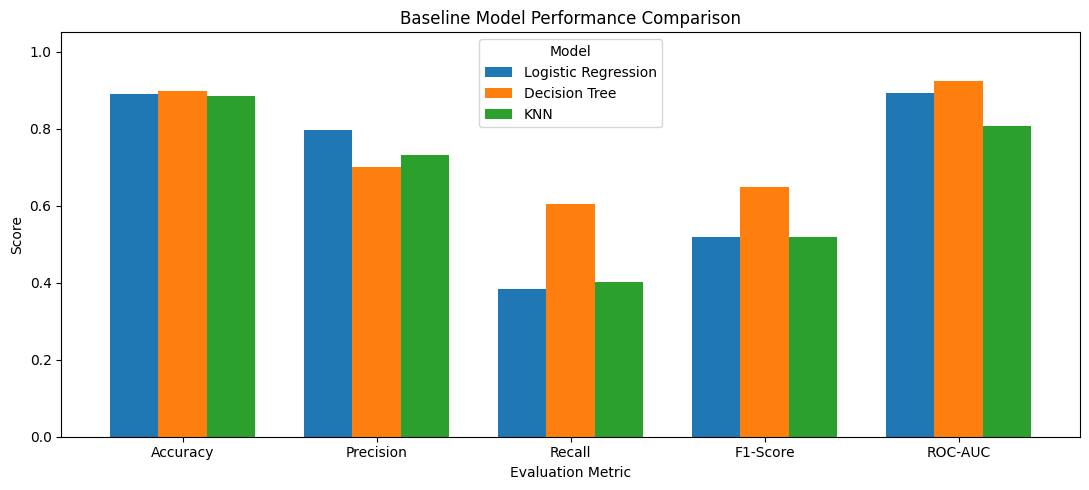

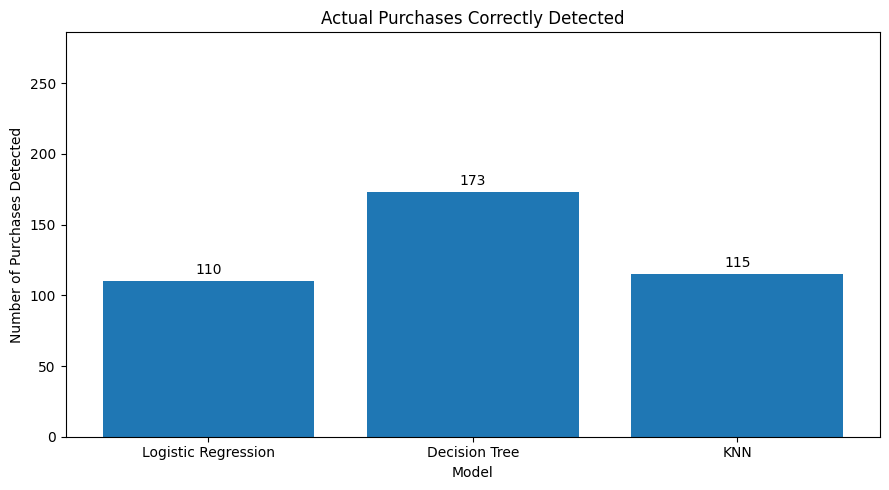


Baseline comparison completed successfully.


In [16]:

# ==================================================
# SECTION 5.4: BASELINE MODEL COMPARISON
# ==================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Collect results from all three models
baseline_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "KNN"
    ],
    "Accuracy": [
        logistic_accuracy,
        tree_accuracy,
        knn_accuracy
    ],
    "Precision": [
        logistic_precision,
        tree_precision,
        knn_precision
    ],
    "Recall": [
        logistic_recall,
        tree_recall,
        knn_recall
    ],
    "F1-Score": [
        logistic_f1,
        tree_f1,
        knn_f1
    ],
    "ROC-AUC": [
        logistic_auc,
        tree_auc,
        knn_auc
    ]
})

# Display comparison table
print("BASELINE MODEL COMPARISON")
print("-" * 55)

display(baseline_results.round(4))

# Identify best baseline by F1-score
best_model = baseline_results.loc[
    baseline_results["F1-Score"].idxmax()
]

print("\nBEST BASELINE BY F1-SCORE")
print("-" * 55)

print("Model:", best_model["Model"])
print(f"F1-Score: {best_model['F1-Score']:.4f}")
print(f"Recall: {best_model['Recall']:.4f}")
print(f"ROC-AUC: {best_model['ROC-AUC']:.4f}")

# --------------------------------------------------
# Graph 1: Model Performance Comparison
# --------------------------------------------------

metrics = ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]

ax = baseline_results.set_index("Model")[metrics].T.plot(
    kind="bar",
    figsize=(11, 5),
    width=0.75
)

plt.title("Baseline Model Performance Comparison")
plt.xlabel("Evaluation Metric")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(title="Model")
plt.tight_layout()
plt.show()

# --------------------------------------------------
# Graph 2: Actual Purchases Detected
# --------------------------------------------------

models = baseline_results["Model"].tolist()

buyers_detected = [
    logistic_cm[1, 1],
    tree_cm[1, 1],
    knn_cm[1, 1]
]

plt.figure(figsize=(9, 5))
bars = plt.bar(models, buyers_detected)

plt.title("Actual Purchases Correctly Detected")
plt.xlabel("Model")
plt.ylabel("Number of Purchases Detected")
plt.ylim(0, 286)

for bar, value in zip(bars, buyers_detected):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 5,
        str(value),
        ha="center"
    )

plt.tight_layout()
plt.show()

print("\nBaseline comparison completed successfully.")



**Findings:**

- We compared Logistic Regression, Decision Tree, and KNN using the same validation dataset.
- The Decision Tree performed best overall, with an F1-score of 64.92%, recall of 60.49%, and ROC-AUC of 92.31%.
- The Decision Tree correctly detected 173 out of 286 purchases, compared with 110 for Logistic Regression and 115 for KNN.
- Logistic Regression had the highest precision at 79.71%, meaning its purchase predictions were more often correct.
- Our results show that the Decision Tree is currently the strongest baseline, but it still misses 113 actual purchases.
- We will investigate ways to improve purchase detection in the next stage of the project.



## 6. Detailed Model Evaluation

### 6.1 Confusion Matrix Visualization

We use confusion matrix heatmaps to compare the predictions made by our three baseline models.

These graphs show how many purchases and non-purchases were correctly or incorrectly predicted.

We are especially interested in false negatives because they represent actual purchases that our models failed to detect.


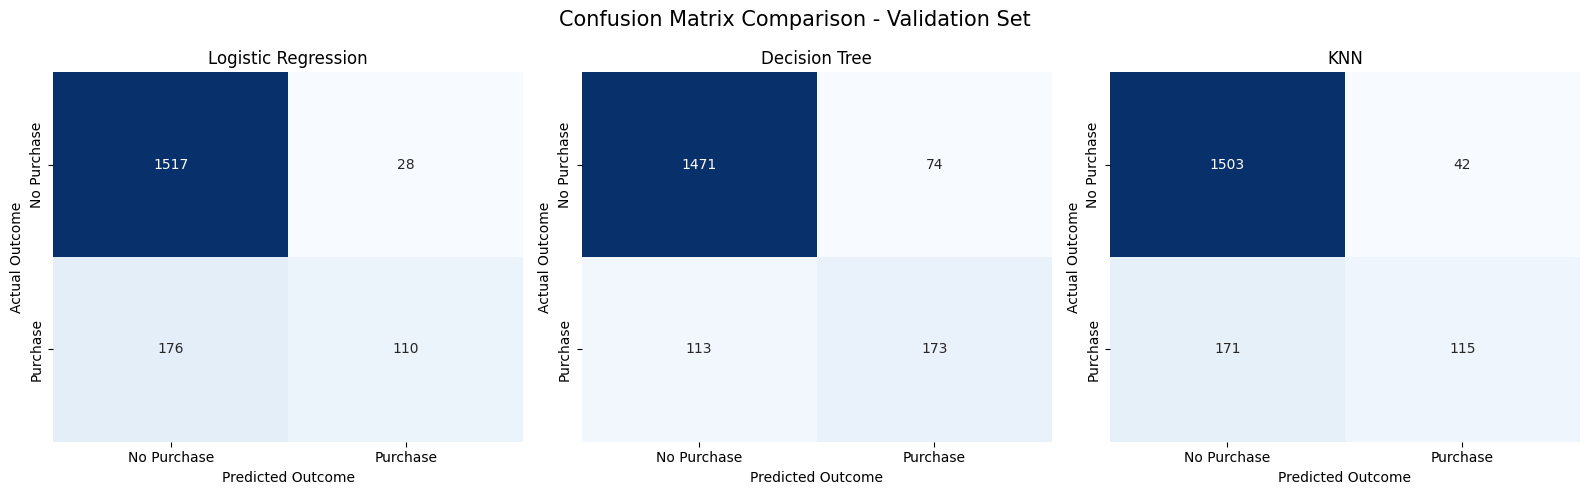

CONFUSION MATRIX SUMMARY
-------------------------------------------------------

Logistic Regression
True Negatives:  1517
False Positives: 28
False Negatives: 176
True Positives:  110

Decision Tree
True Negatives:  1471
False Positives: 74
False Negatives: 113
True Positives:  173

KNN
True Negatives:  1503
False Positives: 42
False Negatives: 171
True Positives:  115

Confusion matrix analysis completed.


In [17]:

# ==================================================
# SECTION 6.1: CONFUSION MATRIX HEATMAPS
# ==================================================

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Use confusion matrices from previous sections
confusion_matrices = {
    "Logistic Regression": logistic_cm,
    "Decision Tree": tree_cm,
    "KNN": knn_cm
}

# Create three heatmaps
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (model_name, cm) in zip(
    axes, confusion_matrices.items()
):
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=["No Purchase", "Purchase"],
        yticklabels=["No Purchase", "Purchase"],
        ax=ax
    )

    ax.set_title(model_name)
    ax.set_xlabel("Predicted Outcome")
    ax.set_ylabel("Actual Outcome")

plt.suptitle(
    "Confusion Matrix Comparison - Validation Set",
    fontsize=15
)

plt.tight_layout()
plt.show()

# Summary of prediction errors
print("CONFUSION MATRIX SUMMARY")
print("-" * 55)

for model_name, cm in confusion_matrices.items():
    tn, fp, fn, tp = cm.ravel()

    print(f"\n{model_name}")
    print(f"True Negatives:  {tn}")
    print(f"False Positives: {fp}")
    print(f"False Negatives: {fn}")
    print(f"True Positives:  {tp}")

print("\nConfusion matrix analysis completed.")



### 6.2 ROC Curve Comparison

We use ROC curves to compare how well our three baseline models distinguish between purchase and non-purchase sessions at different decision thresholds.

The ROC-AUC score summarizes this performance. A higher score indicates better separation between the two classes.

This comparison will help us identify which model is more suitable for further improvement.


ROC-AUC COMPARISON
---------------------------------------------
Logistic Regression: 0.8921
Decision Tree: 0.9231
KNN: 0.8067


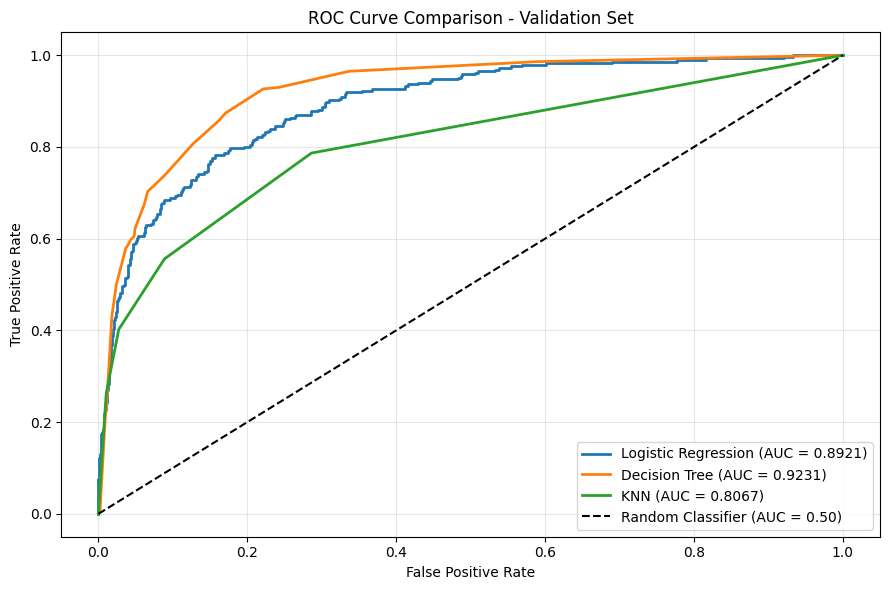


ROC curve comparison completed.


In [18]:

# ==================================================
# SECTION 6.2: ROC CURVE COMPARISON
# ==================================================

from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Models trained in earlier sections
models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": tree_model,
    "KNN": knn_model
}

plt.figure(figsize=(9, 6))

print("ROC-AUC COMPARISON")
print("-" * 45)

for model_name, model in models.items():

    # Predict purchase probabilities
    probabilities = model.predict_proba(X_val_processed)[:, 1]

    # Calculate ROC curve
    fpr, tpr, thresholds = roc_curve(
        y_val, probabilities
    )

    # Calculate ROC-AUC
    auc_score = roc_auc_score(
        y_val, probabilities
    )

    # Plot ROC curve
    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{model_name} (AUC = {auc_score:.4f})"
    )

    print(f"{model_name}: {auc_score:.4f}")

# Random classifier reference
plt.plot(
    [0, 1],
    [0, 1],
    "k--",
    label="Random Classifier (AUC = 0.50)"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison - Validation Set")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("\nROC curve comparison completed.")



### 6.3 Precision-Recall Curve Comparison

Since purchase sessions are much less common than non-purchase sessions, accuracy and ROC-AUC alone are not enough to evaluate our models.

We use precision-recall curves to examine how well each model identifies actual buyers while limiting incorrect purchase predictions.

We also calculate Average Precision (AP) to compare performance across different decision thresholds.


AVERAGE PRECISION COMPARISON
--------------------------------------------------
Logistic Regression: 0.6732
Decision Tree: 0.6821
KNN: 0.5133


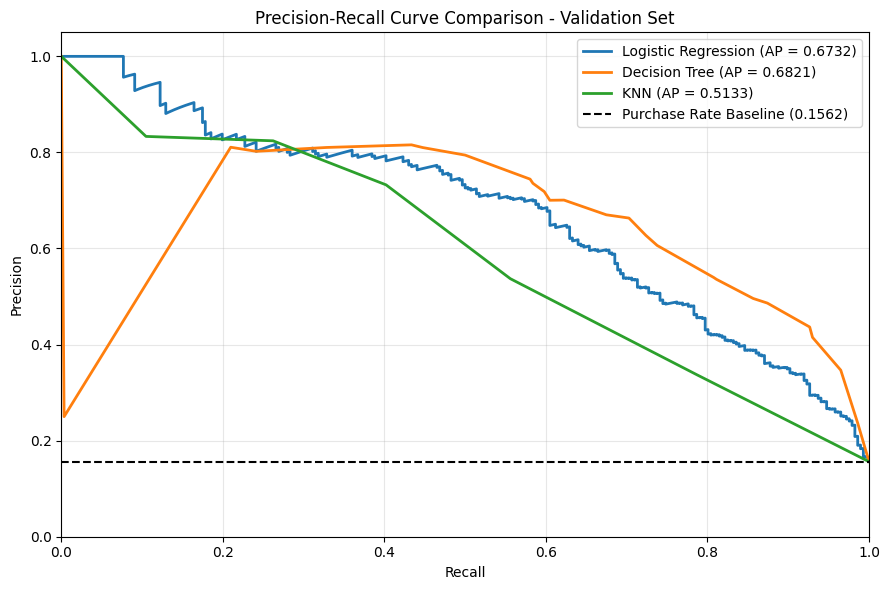


BEST MODEL BY AVERAGE PRECISION
--------------------------------------------------
Model: Decision Tree
Average Precision: 0.6821

Precision-recall comparison completed.


In [19]:

# ==================================================
# SECTION 6.3: PRECISION-RECALL CURVE COMPARISON
# ==================================================

from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

print("AVERAGE PRECISION COMPARISON")
print("-" * 50)

ap_results = {}

for model_name, model in models.items():

    # Predict probability of purchase
    probabilities = model.predict_proba(
        X_val_processed
    )[:, 1]

    # Calculate precision-recall curve
    precision, recall, thresholds = precision_recall_curve(
        y_val, probabilities
    )

    # Calculate average precision
    ap_score = average_precision_score(
        y_val, probabilities
    )

    ap_results[model_name] = ap_score

    plt.plot(
        recall,
        precision,
        linewidth=2,
        label=f"{model_name} (AP = {ap_score:.4f})"
    )

    print(f"{model_name}: {ap_score:.4f}")

# Baseline purchase rate
purchase_rate = y_val.mean()

plt.axhline(
    y=purchase_rate,
    color="black",
    linestyle="--",
    label=f"Purchase Rate Baseline ({purchase_rate:.4f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve Comparison - Validation Set")
plt.legend(loc="best")
plt.grid(alpha=0.3)
plt.xlim(0, 1)
plt.ylim(0, 1.05)
plt.tight_layout()
plt.show()

# Identify best model
best_ap_model = max(ap_results, key=ap_results.get)

print("\nBEST MODEL BY AVERAGE PRECISION")
print("-" * 50)
print(f"Model: {best_ap_model}")
print(f"Average Precision: {ap_results[best_ap_model]:.4f}")

print("\nPrecision-recall comparison completed.")



### 6.4 Baseline Evaluation Findings

We trained and compared three baseline models: Logistic Regression, Decision Tree, and KNN.

The Decision Tree performed best overall on our validation set, with an accuracy of 89.79%, F1-score of 0.6492, ROC-AUC of 0.9231, and Average Precision of 0.6821.

However, the results also show that predicting purchases is more difficult than predicting non-purchases. Only about 15.6% of sessions result in purchases, so accuracy alone does not give a complete picture of model performance.

The Decision Tree correctly identified 173 out of 286 actual purchases, while Logistic Regression identified 110 and KNN identified 115.

Our main findings are:

- The Decision Tree is the strongest baseline based on F1-score, ROC-AUC, and Average Precision.
- Class imbalance is an important challenge because purchase sessions are less common.
- Recall needs improvement because the models still miss many actual purchases.
- The PageValues feature may have a strong influence on predictions and needs further investigation.
- Our current evaluation uses a random stratified split. A later-month evaluation would provide a more realistic check of performance over time.

For the next stage, we plan to improve class imbalance handling, adjust decision thresholds, compare results with and without PageValues, and test stronger models such as gradient boosting.

We also plan to implement a neural network from scratch using NumPy, including forward propagation, backpropagation, and stochastic gradient descent, and compare it with a library implementation.

These improvements will help us move beyond standard baseline models and address the feedback received on our project proposal.



## 7. Initial Experiments

### 7.1 Model Performance With and Without PageValues

During data exploration, we found that PageValues is much higher for purchase sessions than non-purchase sessions.

We want to investigate how much our baseline models depend on this feature.

We will compare Logistic Regression, Decision Tree, and KNN using all 17 original features and then using 16 features without PageValues.

We will keep the same training and validation split, preprocessing methods, and model settings so the comparison is fair.

We will compare accuracy, precision, recall, F1-score, and ROC-AUC to see how removing PageValues affects performance.


WITH VS WITHOUT PAGEVALUES
-------------------------------------------------------


,Model,Accuracy_With,Precision_With,Recall_With,F1-Score_With,ROC-AUC_With,Accuracy_Without,Precision_Without,Recall_Without,F1-Score_Without,ROC-AUC_Without
0,Logistic Regression,0.8886,0.7971,0.3846,0.5189,0.8921,0.8443,0.5238,0.0385,0.0717,0.7389
1,Decision Tree,0.8979,0.7004,0.6049,0.6492,0.9231,0.8438,0.5000,0.0664,0.1173,0.7430
2,KNN,0.8837,0.7325,0.4021,0.5192,0.8067,0.8329,0.4123,0.1643,0.2350,0.6592



PERFORMANCE DIFFERENCES
-------------------------------------------------------


,Model,F1 With,F1 Without,F1 Difference,AUC With,AUC Without,AUC Difference
0,Logistic Regression,0.5189,0.0717,-0.4472,0.8921,0.7389,-0.1532
1,Decision Tree,0.6492,0.1173,-0.5319,0.9231,0.7430,-0.1801
2,KNN,0.5192,0.2350,-0.2842,0.8067,0.6592,-0.1475


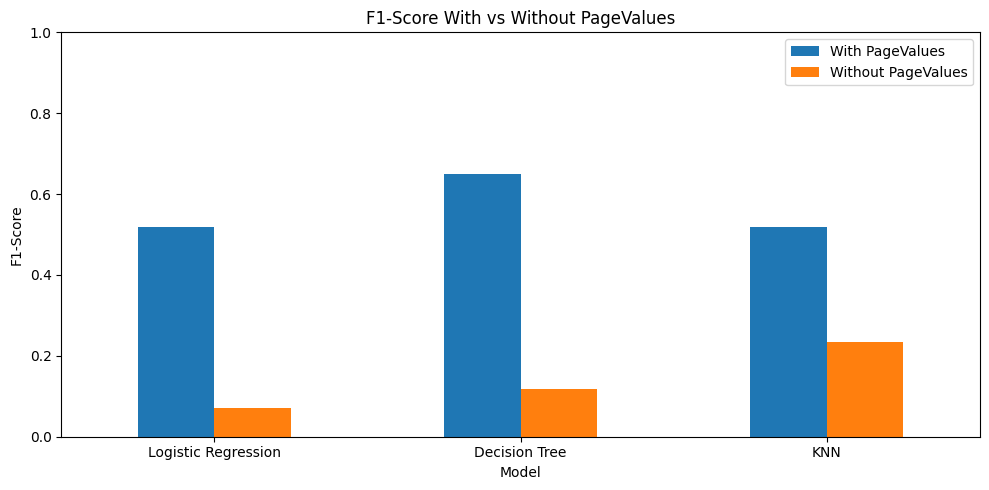


PageValues experiment completed.


In [20]:

# ==================================================
# SECTION 7.1: WITH VS WITHOUT PAGEVALUES
# ==================================================

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score
)
import pandas as pd
import matplotlib.pyplot as plt

# --------------------------------------------------
# 1. Remove PageValues from feature lists
# --------------------------------------------------

numerical_without_pagevalues = [
    feature for feature in numerical_features
    if feature != "PageValues"
]

# --------------------------------------------------
# 2. Create preprocessing without PageValues
# --------------------------------------------------

preprocessor_without_pagevalues = ColumnTransformer(
    transformers=[
        (
            "num",
            clone(numerical_scaler),
            numerical_without_pagevalues
        ),
        (
            "cat",
            clone(categorical_encoder),
            categorical_features
        ),
        (
            "bool",
            "passthrough",
            boolean_features
        )
    ]
)

# --------------------------------------------------
# 3. Define the same baseline models
# --------------------------------------------------

experiment_models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=5,
        random_state=42
    ),
    "KNN": KNeighborsClassifier(
        n_neighbors=5
    )
}

# --------------------------------------------------
# 4. Train and evaluate without PageValues
# --------------------------------------------------

results_without_pagevalues = []

for model_name, model in experiment_models.items():

    pipeline = Pipeline([
        ("preprocessing", clone(
            preprocessor_without_pagevalues
        )),
        ("model", clone(model))
    ])

    # Remove PageValues from input
    X_train_no_pv = X_train.drop(columns=["PageValues"])
    X_val_no_pv = X_val.drop(columns=["PageValues"])

    # Fit using training data only
    pipeline.fit(X_train_no_pv, y_train)

    # Predict validation outcomes
    predictions = pipeline.predict(X_val_no_pv)

    probabilities = pipeline.predict_proba(
        X_val_no_pv
    )[:, 1]

    results_without_pagevalues.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1-Score": f1_score(
            y_val, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_val, probabilities
        )
    })

without_pv_results = pd.DataFrame(
    results_without_pagevalues
)

# --------------------------------------------------
# 5. Compare with original baseline results
# --------------------------------------------------

with_pv_results = baseline_results.copy()

comparison = with_pv_results.merge(
    without_pv_results,
    on="Model",
    suffixes=("_With", "_Without")
)

print("WITH VS WITHOUT PAGEVALUES")
print("-" * 55)

display(comparison.round(4))

# --------------------------------------------------
# 6. Calculate performance differences
# --------------------------------------------------

difference_table = pd.DataFrame({
    "Model": comparison["Model"],
    "F1 With": comparison["F1-Score_With"],
    "F1 Without": comparison["F1-Score_Without"],
    "F1 Difference": (
        comparison["F1-Score_Without"]
        - comparison["F1-Score_With"]
    ),
    "AUC With": comparison["ROC-AUC_With"],
    "AUC Without": comparison["ROC-AUC_Without"],
    "AUC Difference": (
        comparison["ROC-AUC_Without"]
        - comparison["ROC-AUC_With"]
    )
})

print("\nPERFORMANCE DIFFERENCES")
print("-" * 55)

display(difference_table.round(4))

# --------------------------------------------------
# 7. Visualize F1-score comparison
# --------------------------------------------------

plot_data = comparison.set_index("Model")[
    ["F1-Score_With", "F1-Score_Without"]
]

plot_data.columns = [
    "With PageValues",
    "Without PageValues"
]

plot_data.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("F1-Score With vs Without PageValues")
plt.xlabel("Model")
plt.ylabel("F1-Score")
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()
plt.show()

print("\nPageValues experiment completed.")



**Findings**

Removing PageValues caused a large decrease in performance for all three baseline models. Logistic Regression's F1-score dropped from 0.5189 to 0.0717, Decision Tree's from 0.6492 to 0.1173, and KNN's from 0.5192 to 0.2350.

These results show that PageValues provides important information for predicting purchases. However, the models rely heavily on this feature, so we need to investigate whether it is available before a customer completes their shopping session.

In later experiments, we will also explore ways to improve performance without relying so much on PageValues.



### 7.2 Handling Class Imbalance

Our dataset contains many more non-purchase sessions than purchase sessions. This imbalance can cause models to favor the majority class and miss actual buyers.

To address this, we will compare the original Logistic Regression and Decision Tree models with versions using balanced class weights.

Balanced class weights give more importance to the minority class during training. We will compare precision, recall, F1-score, and ROC-AUC on the same validation set to see whether this improves purchase prediction.


CLASS IMBALANCE EXPERIMENT


,Model,Accuracy_Original,Precision_Original,Recall_Original,F1-Score_Original,ROC-AUC_Original,Accuracy_Balanced,Precision_Balanced,Recall_Balanced,F1-Score_Balanced,ROC-AUC_Balanced
0,Logistic Regression,0.8886,0.7971,0.3846,0.5189,0.8921,0.8433,0.4989,0.7797,0.6085,0.9021
1,Decision Tree,0.8979,0.7004,0.6049,0.6492,0.9231,0.8356,0.4855,0.8776,0.6252,0.9222


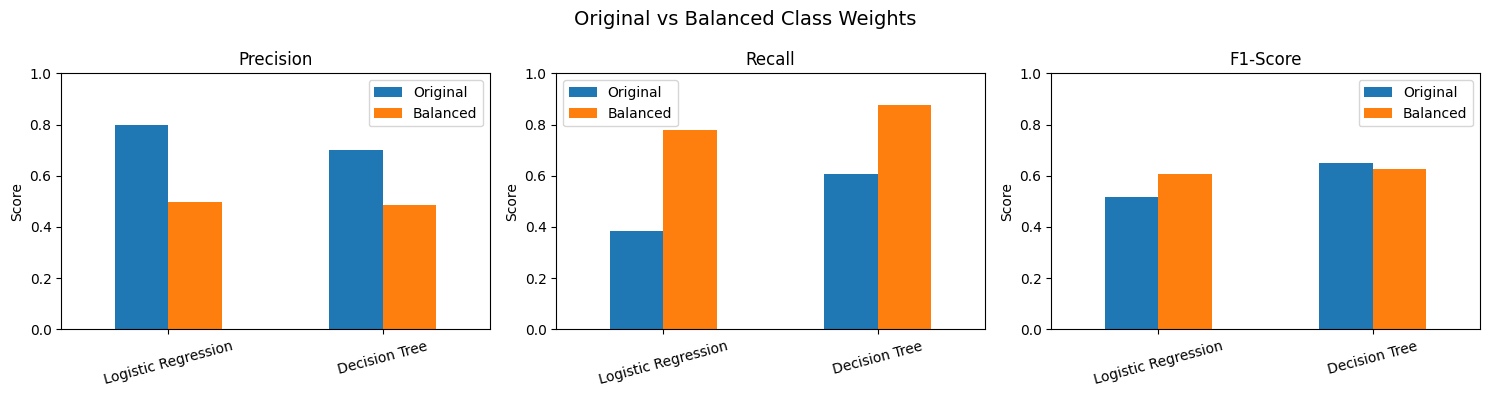

Logistic Regression recall change: +0.3951
Decision Tree recall change: +0.2727


In [21]:

# ==================================================
# SECTION 7.2: CLASS IMBALANCE HANDLING
# ==================================================

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix
)
import pandas as pd
import matplotlib.pyplot as plt

# 1. Train models with balanced class weights

balanced_models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=5,
        class_weight="balanced",
        random_state=42
    )
}

balanced_results = []

for name, model in balanced_models.items():

    model.fit(X_train_processed, y_train)

    predictions = model.predict(X_val_processed)
    probabilities = model.predict_proba(
        X_val_processed
    )[:, 1]

    balanced_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1-Score": f1_score(
            y_val, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_val, probabilities)
    })

balanced_results_df = pd.DataFrame(balanced_results)

# 2. Compare against original baselines

original_results = baseline_results[
    baseline_results["Model"].isin(balanced_models.keys())
].copy()

comparison_72 = original_results.merge(
    balanced_results_df,
    on="Model",
    suffixes=("_Original", "_Balanced")
)

print("CLASS IMBALANCE EXPERIMENT")
display(comparison_72.round(4))

# 3. Show changes in precision, recall and F1

metrics = ["Precision", "Recall", "F1-Score"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, metric in zip(axes, metrics):

    comparison_72.plot(
        x="Model",
        y=[f"{metric}_Original",
           f"{metric}_Balanced"],
        kind="bar",
        ax=ax
    )

    ax.set_title(metric)
    ax.set_ylabel("Score")
    ax.set_xlabel("")
    ax.set_ylim(0, 1)
    ax.tick_params(axis="x", rotation=15)
    ax.legend(["Original", "Balanced"])

plt.suptitle(
    "Original vs Balanced Class Weights",
    fontsize=14
)
plt.tight_layout()
plt.show()

# 4. Print the change in recall

for _, row in comparison_72.iterrows():

    recall_change = (
        row["Recall_Balanced"]
        - row["Recall_Original"]
    )

    print(
        f"{row['Model']} recall change: "
        f"{recall_change:+.4f}"
    )



### Findings

Using balanced class weights improved recall for both Logistic Regression and Decision Tree. Logistic Regression's recall increased from 38.46% to 77.97%, while Decision Tree's recall increased from 60.49% to 87.76%.

However, precision decreased for both models, meaning they made more false purchase predictions. Logistic Regression's F1-score improved, while Decision Tree's F1-score decreased slightly.

These results show that balanced class weights help identify more actual buyers, but there is a trade-off between precision and recall. We will explore different prediction thresholds in the next experiment to find a better balance.



### 7.3 Decision Threshold Tuning

In the previous experiment, balanced class weights improved recall but reduced precision. We will now test different prediction thresholds to find a better balance between identifying actual buyers and avoiding false purchase predictions.

We will compare thresholds from 0.20 to 0.80 using Logistic Regression and Decision Tree with balanced class weights. We will evaluate precision, recall, and F1-score on the validation set.


THRESHOLD COMPARISON


,Model,Threshold,Precision,Recall,F1-Score
0,Logistic Regression,0.20,0.2614,0.9790,0.4127
1,Logistic Regression,0.25,0.2978,0.9476,0.4532
2,Logistic Regression,0.30,0.3325,0.9231,0.4889
3,Logistic Regression,0.35,0.3695,0.9056,0.5248
4,Logistic Regression,0.40,0.4003,0.8566,0.5457
5,Logistic Regression,0.45,0.4476,0.8217,0.5795
6,Logistic Regression,0.50,0.4989,0.7797,0.6085
7,Logistic Regression,0.55,0.5389,0.7273,0.6190
8,Logistic Regression,0.60,0.6075,0.6818,0.6425
9,Logistic Regression,0.65,0.6344,0.6189,0.6265



BEST THRESHOLD FOR EACH MODEL


,Model,Threshold,Precision,Recall,F1-Score
0,Decision Tree,0.65,0.6467,0.7168,0.6799
1,Logistic Regression,0.60,0.6075,0.6818,0.6425


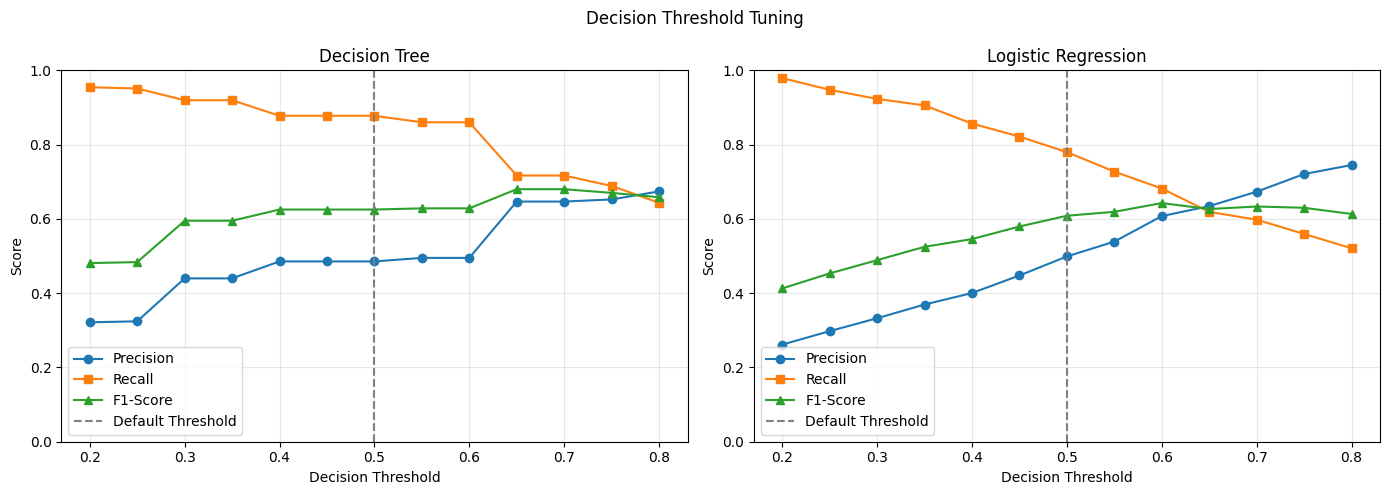

In [22]:

# ================================================
# SECTION 7.3: DECISION THRESHOLD TUNING
# ================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

# 1. Thresholds to test
thresholds = np.arange(0.20, 0.81, 0.05)

threshold_results = []

# 2. Use balanced models from Section 7.2
for name, model in balanced_models.items():

    # Refit the model on training data only
    model.fit(X_train_processed, y_train)

    # Get validation purchase probabilities
    probabilities = model.predict_proba(
        X_val_processed
    )[:, 1]

    for threshold in thresholds:

        predictions = (
            probabilities >= threshold
        ).astype(int)

        threshold_results.append({
            "Model": name,
            "Threshold": round(float(threshold), 2),
            "Precision": precision_score(
                y_val, predictions, zero_division=0
            ),
            "Recall": recall_score(
                y_val, predictions, zero_division=0
            ),
            "F1-Score": f1_score(
                y_val, predictions, zero_division=0
            )
        })

threshold_df = pd.DataFrame(threshold_results)

# 3. Display all threshold results
print("THRESHOLD COMPARISON")
display(threshold_df.round(4))

# 4. Find best threshold by validation F1
best_thresholds = (
    threshold_df
    .sort_values(
        ["Model", "F1-Score"],
        ascending=[True, False]
    )
    .groupby("Model")
    .head(1)
    .reset_index(drop=True)
)

print("\nBEST THRESHOLD FOR EACH MODEL")
display(best_thresholds.round(4))

# 5. Plot precision, recall, and F1
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (name, group) in zip(
    axes, threshold_df.groupby("Model")
):

    ax.plot(
        group["Threshold"],
        group["Precision"],
        marker="o",
        label="Precision"
    )

    ax.plot(
        group["Threshold"],
        group["Recall"],
        marker="s",
        label="Recall"
    )

    ax.plot(
        group["Threshold"],
        group["F1-Score"],
        marker="^",
        label="F1-Score"
    )

    ax.axvline(
        0.50,
        linestyle="--",
        color="gray",
        label="Default Threshold"
    )

    ax.set_title(name)
    ax.set_xlabel("Decision Threshold")
    ax.set_ylabel("Score")
    ax.set_ylim(0, 1)
    ax.grid(alpha=0.3)
    ax.legend()

plt.suptitle("Decision Threshold Tuning")
plt.tight_layout()
plt.show()



### Findings

Testing different prediction thresholds helped us find a better balance between precision and recall. The best threshold for Logistic Regression was 0.60, giving an F1-score of 0.6425, while Decision Tree performed best at 0.65 with an F1-score of 0.6799.

As the threshold increased, precision generally improved while recall decreased. This shows that lower thresholds identify more potential buyers but also produce more false positives.

Overall, Decision Tree achieved the highest F1-score in this experiment. We will use these validation results to guide our model selection and evaluate the chosen settings on unseen data later.



### 7.4 Plan for Later-Month Testing

Our current models use a random split, which means shopping sessions from different months can appear in both the training and validation sets.

To evaluate how well our models generalize to future shopping sessions, we plan to conduct a separate month-based experiment. We will train the models using earlier months and evaluate them using later months, keeping those sessions separate during training.

The dataset contains month labels but does not provide exact session dates or years, so this will be an approximate time-based evaluation rather than a fully chronological test.

We will compare the results with our current random-split baselines to see whether model performance changes when predicting purchases from later months. This will help us better understand how reliable our models might be on new shopping sessions.



## 8. Prediction Demonstration

### 8.1 Sample Purchase Predictions

We will use our Decision Tree model with balanced class weights and the selected threshold of 0.65 to demonstrate purchase predictions.

We will select five sessions from the validation set and compare their predicted outcomes with the actual results. This will help us understand how the model works on individual shopping sessions.


In [23]:

# ================================================
# SECTION 8.1: SAMPLE PURCHASE PREDICTIONS
# ================================================

import numpy as np
import pandas as pd

# Use the balanced Decision Tree from Section 7.2
model = balanced_models["Decision Tree"]

# Selected threshold from Section 7.3
selected_threshold = 0.65

# Get predicted purchase probabilities
purchase_probabilities = model.predict_proba(
    X_val_processed
)[:, 1]

# Apply our selected threshold
predicted_labels = (
    purchase_probabilities >= selected_threshold
).astype(int)

# Build a table of validation predictions
prediction_demo = pd.DataFrame({
    "Actual Purchase": np.asarray(y_val),
    "Predicted Purchase": predicted_labels,
    "Purchase Probability": purchase_probabilities
})

# Convert 0/1 labels to readable text
prediction_demo["Actual Purchase"] = (
    prediction_demo["Actual Purchase"]
    .map({0: "No", 1: "Yes"})
)

prediction_demo["Predicted Purchase"] = (
    prediction_demo["Predicted Purchase"]
    .map({0: "No", 1: "Yes"})
)

# Select five reproducible example sessions
sample_predictions = prediction_demo.sample(
    n=5,
    random_state=42
).copy()

sample_predictions.insert(
    0,
    "Session",
    sample_predictions.index + 1
)

print("SAMPLE PURCHASE PREDICTIONS")
display(
    sample_predictions.round(4).reset_index(drop=True)
)

# Check whether each prediction is correct
sample_predictions["Correct"] = (
    sample_predictions["Actual Purchase"]
    == sample_predictions["Predicted Purchase"]
)

print("\nCORRECT PREDICTIONS IN SAMPLE:",
      sample_predictions["Correct"].sum(),
      "out of 5")


SAMPLE PURCHASE PREDICTIONS


,Session,Actual Purchase,Predicted Purchase,Purchase Probability
0,248,Yes,Yes,0.9715
1,1294,Yes,No,0.6009
2,1564,No,No,0.0047
3,1102,No,No,0.0047
4,1162,No,No,0.0556



CORRECT PREDICTIONS IN SAMPLE: 4 out of 5



### Findings

The Decision Tree model correctly predicted 4 out of 5 sample shopping sessions. It successfully identified one purchase and three non-purchases.

However, it missed one actual purchase because its predicted probability (0.6009) was below our selected threshold of 0.65.

This example shows how the decision threshold affects individual predictions. Although the model performed well on these five examples, we need to use the full validation set to evaluate its overall performance.





### 8.2 Purchase Probability Visualization

Instead of only predicting Yes or No, our Decision Tree model also provides an estimated probability of purchase for each shopping session.

We will visualize the probabilities for ten validation sessions and compare them with our selected decision threshold of 0.65. This helps us understand how the model makes purchase predictions.




PURCHASE PROBABILITIES FOR 10 SESSIONS


,Session,Actual Purchase,Predicted Purchase,Purchase Probability
1101,1102,No,No,0.0047
1563,1564,No,No,0.0047
275,276,No,No,0.0047
643,644,No,No,0.0047
382,383,No,No,0.0556
1161,1162,No,No,0.0556
1197,1198,No,No,0.1714
777,778,No,No,0.1714
1293,1294,Yes,No,0.6009
247,248,Yes,Yes,0.9715


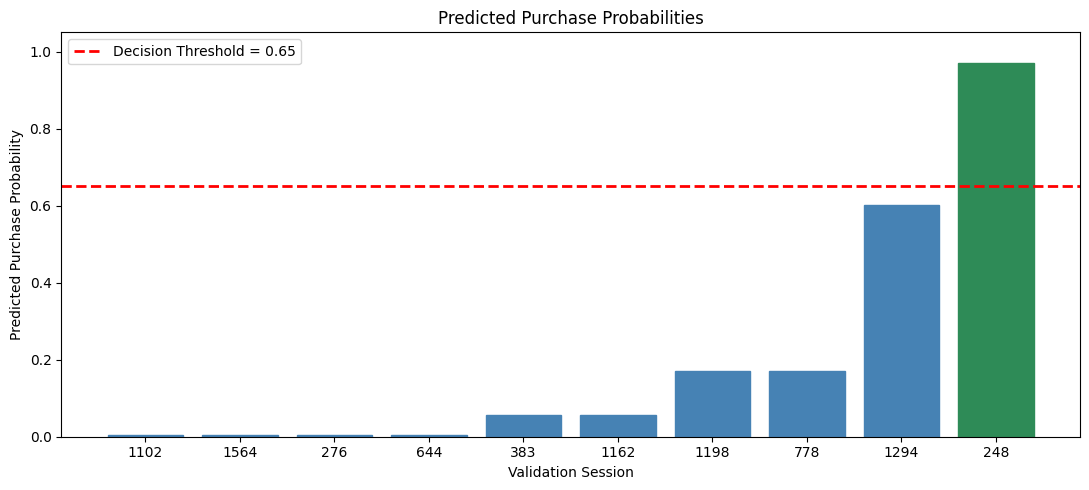


Sessions predicted as purchase: 1
Sessions predicted as no purchase: 9


In [24]:

# ================================================
# SECTION 8.2: PURCHASE PROBABILITIES
# ================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Reuse the predictions from Section 8.1
# Select 10 reproducible validation sessions
probability_samples = prediction_demo.sample(
    n=10,
    random_state=42
).copy()

probability_samples["Session"] = (
    probability_samples.index + 1
)

# Sort by purchase probability
probability_samples = probability_samples.sort_values(
    "Purchase Probability"
)

# Display probability table
print("PURCHASE PROBABILITIES FOR 10 SESSIONS")

display(
    probability_samples[
        [
            "Session",
            "Actual Purchase",
            "Predicted Purchase",
            "Purchase Probability"
        ]
    ].round(4)
)

# Plot predicted probabilities
plt.figure(figsize=(11, 5))

bars = plt.bar(
    probability_samples["Session"].astype(str),
    probability_samples["Purchase Probability"]
)

# Show selected decision threshold
plt.axhline(
    y=selected_threshold,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Decision Threshold = 0.65"
)

# Color bars based on predicted purchase
for bar, prediction in zip(
    bars,
    probability_samples["Predicted Purchase"]
):
    bar.set_color(
        "seagreen" if prediction == "Yes"
        else "steelblue"
    )

plt.title("Predicted Purchase Probabilities")
plt.xlabel("Validation Session")
plt.ylabel("Predicted Purchase Probability")
plt.ylim(0, 1.05)
plt.legend()
plt.tight_layout()
plt.show()

print("\nSessions predicted as purchase:",
      (probability_samples["Predicted Purchase"] == "Yes").sum())

print("Sessions predicted as no purchase:",
      (probability_samples["Predicted Purchase"] == "No").sum())



### Findings

The model predicted 1 purchase and 9 non-purchases among the 10 sample sessions. Most non-purchase sessions had low predicted probabilities, while Session 248 had a high purchase probability of 0.9715 and was correctly classified.

However, Session 1294 was an actual purchase with a predicted probability of 0.6009. Since this was below our selected threshold of 0.65, the model incorrectly predicted no purchase.

This visualization shows how predicted probabilities and decision thresholds work together to determine the final prediction. It also shows that the model can miss actual buyers even when their predicted purchase probability is relatively high.



## 9. Notebook Summary

This notebook presents the initial implementation of ShopInsight AI for predicting online shopping purchases.

We completed data exploration, preprocessing, and baseline model training using Logistic Regression, Decision Tree, and KNN. We also evaluated model performance, investigated the importance of PageValues, tested balanced class weights, and tuned prediction thresholds.

The balanced Decision Tree achieved the highest validation F1-score of 0.6799 using a threshold of 0.65.

The next milestone will focus on implementing a neural network from scratch, comparing stronger models, conducting later-month evaluation, and testing the final selected model on unseen data.
